<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS06_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Regresi — Praktikum 1, Praktikum 2, dan Tugas

# Praktikum 1 — Regresi Linier

## Langkah 1: Persiapan Data

Unduh atau siapkan file `dataset.csv`. File ini berisi data pelanggan, termasuk `Time on App`, `Time on Website`, `Length of Membership`, dan `Yearly Amount Spent`.

## Langkah 2: Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
import os

# Unggah file CSV jika belum tersedia di sesi Colab.
file_wajib = ["dataset.csv", "Posisi_gaji.csv", "insurance.csv"]
file_belum_ada = [nama for nama in file_wajib if not os.path.exists(nama)]

if file_belum_ada:
    print("Silakan pilih ketiga file CSV yang diperlukan.")
    uploaded = files.upload()
else:
    print("Semua file CSV sudah tersedia.")

Silakan pilih ketiga file CSV yang diperlukan.


Saving insurance.csv to insurance.csv
Saving Posisi_gaji.csv to Posisi_gaji.csv
Saving dataset.csv to dataset.csv


## Langkah 3: Baca Data

In [2]:
data = pd.read_csv("dataset.csv")
data.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


## Langkah 4: Pemahaman terhadap Data

In [3]:
# Melihat beberapa data awal
display(data.head())

# Mengecek ukuran data
print("Ukuran data:", data.shape)

# Informasi tentang data
data.info()

# Deskripsi statistik kolom numerik
display(data.describe())

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


Ukuran data: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


## Langkah 5: Visualisasi Data

### Pairplot

Pairplot memperlihatkan hubungan fitur numerik dengan target `Yearly Amount Spent`.

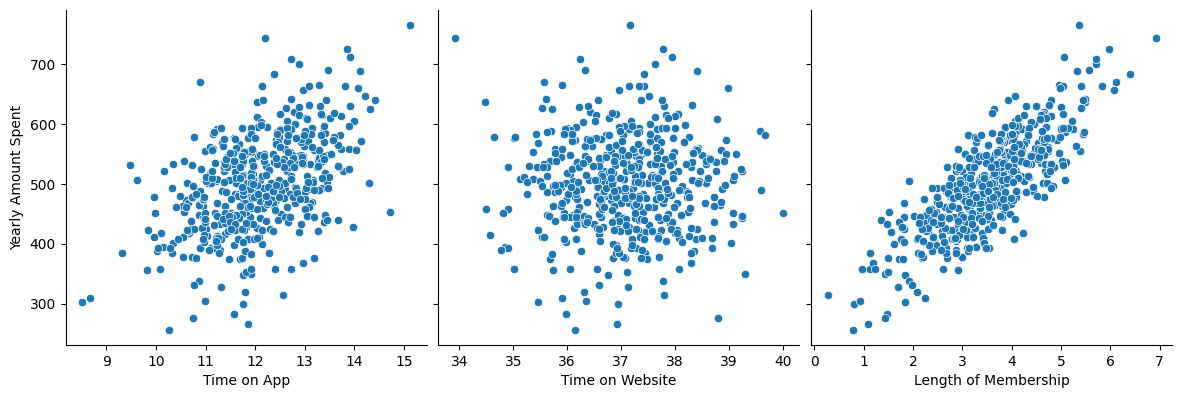

In [4]:
sns.pairplot(
    data,
    x_vars=["Time on App", "Time on Website", "Length of Membership"],
    y_vars="Yearly Amount Spent",
    height=4,
    aspect=1,
    kind="scatter"
)
plt.show()

### Heatmap Korelasi

Korelasi dihitung hanya pada kolom numerik.

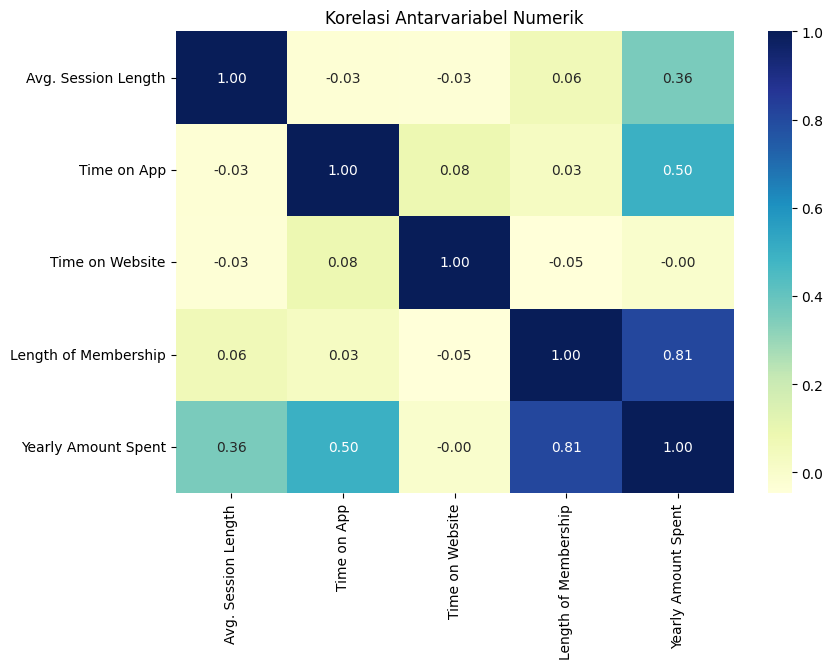

In [5]:
data_numerik = data.select_dtypes(include=np.number)

plt.figure(figsize=(9, 6))
sns.heatmap(data_numerik.corr(), cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Korelasi Antarvariabel Numerik")
plt.show()

## Langkah 6: Regresi Linier

`Length of Membership` digunakan sebagai variabel bebas (`X`) dan `Yearly Amount Spent` sebagai variabel target (`y`).

In [6]:
X = data["Length of Membership"]
y = data["Yearly Amount Spent"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.7,
    test_size=0.3,
    random_state=100
)

import statsmodels.api as sm

# Tambahkan konstanta (intercept)
X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

# Ringkasan model
print(lr.summary())

                             OLS Regression Results                            
Dep. Variable:     Yearly Amount Spent   R-squared:                       0.669
Model:                             OLS   Adj. R-squared:                  0.668
Method:                  Least Squares   F-statistic:                     702.9
Date:                 Mon, 19 Oct 2026   Prob (F-statistic):           1.59e-85
Time:                         15:40:24   Log-Likelihood:                -1841.3
No. Observations:                  350   AIC:                             3687.
Df Residuals:                      348   BIC:                             3694.
Df Model:                            1                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                 

### Visualisasi Garis Regresi pada Data Latih

Garis regresi dibuat dari koefisien model yang benar-benar dilatih, bukan menggunakan koefisien tetap.

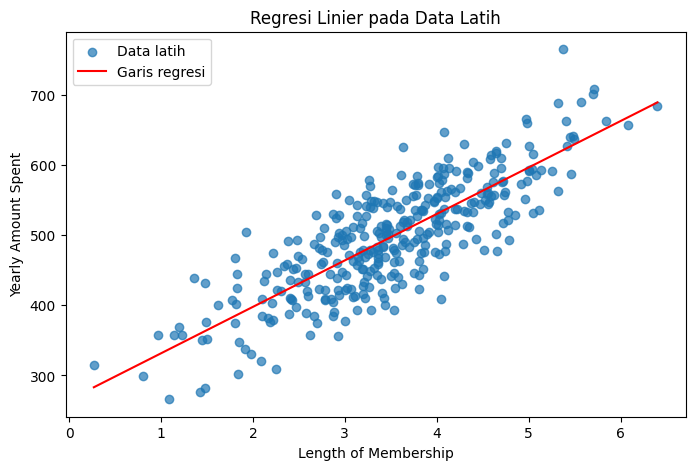

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train, y_train, alpha=0.7, label="Data latih")

x_garis = np.linspace(X_train.min(), X_train.max(), 100)
x_garis_sm = sm.add_constant(x_garis)
y_garis = lr.predict(x_garis_sm)

plt.plot(x_garis, y_garis, "r", label="Garis regresi")
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.title("Regresi Linier pada Data Latih")
plt.legend()
plt.show()

## Langkah 7: Analisis Residual

Residual adalah selisih nilai target sebenarnya dengan nilai prediksi.

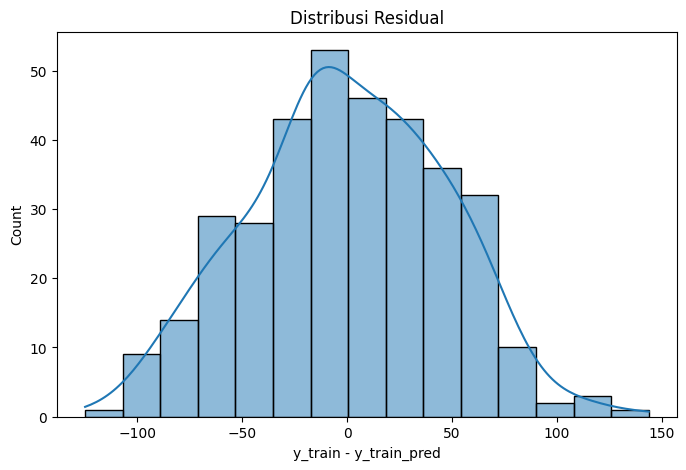

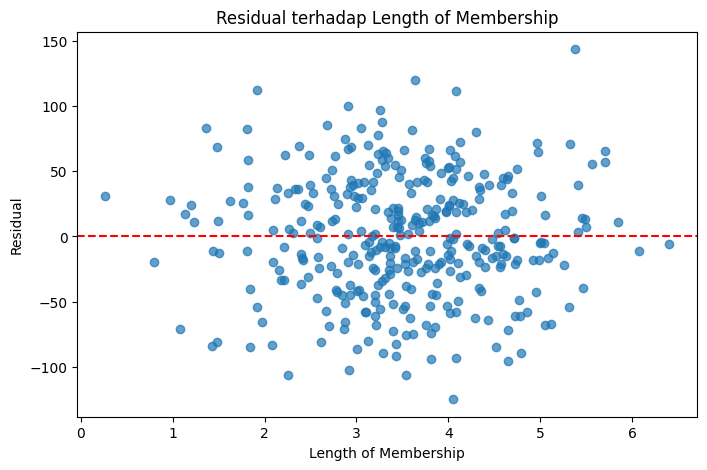

In [8]:
y_train_pred = lr.predict(X_train_sm)
res = y_train - y_train_pred

# Histogram residual
plt.figure(figsize=(8, 5))
sns.histplot(res, bins=15, kde=True)
plt.title("Distribusi Residual")
plt.xlabel("y_train - y_train_pred")
plt.show()

# Scatter plot residual
plt.figure(figsize=(8, 5))
plt.scatter(X_train, res, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Length of Membership")
plt.ylabel("Residual")
plt.title("Residual terhadap Length of Membership")
plt.show()

## Langkah 8: Prediksi pada Data Uji dan Evaluasi Model

In [9]:
from sklearn.metrics import r2_score

X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

r_squared = r2_score(y_test, y_test_pred)
print("R-squared pada data uji:", r_squared)

R-squared pada data uji: 0.611948913768747


## Langkah 9: Visualisasi Hasil

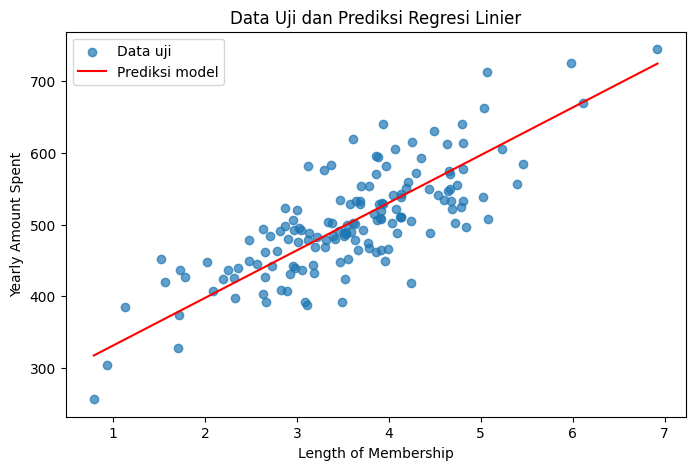

In [10]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, alpha=0.7, label="Data uji")
urutan = np.argsort(X_test.to_numpy())
plt.plot(
    X_test.to_numpy()[urutan],
    y_test_pred.to_numpy()[urutan],
    "r",
    label="Prediksi model"
)
plt.xlabel("Length of Membership")
plt.ylabel("Yearly Amount Spent")
plt.title("Data Uji dan Prediksi Regresi Linier")
plt.legend()
plt.show()

# Praktikum 2 — Support Vector Regression (SVR)

Praktikum ini menggunakan dataset `Posisi_gaji.csv`. Fitur yang digunakan adalah `Level`, sedangkan targetnya adalah `Gaji`.

## 1. Mengimpor Library

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## 2. Mengimpor Dataset

In [12]:
dataset = pd.read_csv("Posisi_gaji.csv")

display(dataset)

X_svr = dataset.iloc[:, 1:2].values  # Kolom Level
y_svr = dataset.iloc[:, 2].values    # Kolom Gaji

print("Ukuran X:", X_svr.shape)
print("Ukuran y:", y_svr.shape)

,Posisi,Level,Gaji
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


Ukuran X: (10, 1)
Ukuran y: (10,)


## 3. Feature Scaling

SVR sensitif terhadap skala data, sehingga fitur dan target diskalakan secara terpisah.

In [13]:
from sklearn.preprocessing import StandardScaler

sc_X = StandardScaler()
sc_y = StandardScaler()

X_svr_scaled = sc_X.fit_transform(X_svr)
y_svr_scaled = sc_y.fit_transform(y_svr.reshape(-1, 1)).ravel()

## 4. Fitting SVR ke Dataset

In [14]:
from sklearn.svm import SVR

regressor = SVR(kernel="rbf")
regressor.fit(X_svr_scaled, y_svr_scaled)

SVR()

## 5. Visualisasi Hasil SVR

Titik merah adalah data gaji yang telah diskalakan, sedangkan garis biru adalah prediksi SVR. Sumbu ditampilkan dalam skala asli agar mudah dibaca.

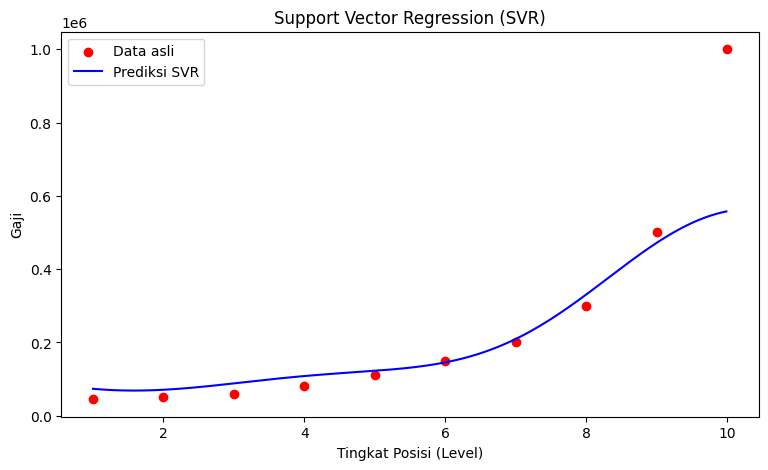

In [15]:
X_grid = np.arange(X_svr.min(), X_svr.max(), 0.01).reshape(-1, 1)
X_grid_scaled = sc_X.transform(X_grid)

y_grid_scaled = regressor.predict(X_grid_scaled).reshape(-1, 1)
y_grid = sc_y.inverse_transform(y_grid_scaled)

plt.figure(figsize=(9, 5))
plt.scatter(X_svr, y_svr, color="red", label="Data asli")
plt.plot(X_grid, y_grid, color="blue", label="Prediksi SVR")
plt.title("Support Vector Regression (SVR)")
plt.xlabel("Tingkat Posisi (Level)")
plt.ylabel("Gaji")
plt.legend()
plt.show()

## 6. Prediksi Hasil

Contoh: memprediksi gaji pada tingkat posisi 6.5.

In [16]:
tingkat_posisi_prediksi = np.array([[6.5]])

posisi_scaled = sc_X.transform(tingkat_posisi_prediksi)
gaji_scaled = regressor.predict(posisi_scaled).reshape(-1, 1)
gaji_prediksi = sc_y.inverse_transform(gaji_scaled)

print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0, 0])

Prediksi Gaji untuk Tingkat Posisi 6.5: 170370.02040650236


## 7. Menampilkan Hasil

Nilai prediksi ditampilkan dalam satuan gaji yang digunakan pada dataset.

In [17]:
print(f"Prediksi gaji pada level 6.5: {gaji_prediksi[0, 0]:,.2f}")

Prediksi gaji pada level 6.5: 170,370.02


## 8. Validasi Hasil

Bandingkan grafik dengan hasil prediksi yang tercetak. Nilai dapat sedikit berbeda dari contoh modul jika versi library atau parameter model berbeda.

## 9. Evaluasi Model SVR

Metrik di bawah dihitung pada data yang digunakan untuk melatih model, sehingga merupakan evaluasi pada data pelatihan.

In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y_svr
y_pred_scaled = regressor.predict(X_svr_scaled).reshape(-1, 1)
y_pred = sc_y.inverse_transform(y_pred_scaled).ravel()

mae = mean_absolute_error(y_actual, y_pred)
mse = mean_squared_error(y_actual, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 63332.392089689674
MSE: 20036494264.13176
RMSE: 141550.3241399742
R-squared: 0.7516001070620797


# Tugas Praktikum — Multiple Linear Regression dengan Dataset Medical Cost Personal Datasets

## Instruksi Umum

Tugas ini menggunakan `insurance.csv` untuk memprediksi biaya medis personal (`charges`). Dataset memiliki fitur numerik (`age`, `bmi`, `children`) dan fitur kategorikal (`sex`, `smoker`, `region`). Fitur kategorikal diubah menjadi numerik menggunakan One-Hot Encoding.

## Tugas 1: Multiple Linear Regression

Langkah yang dilakukan:
1. Mengidentifikasi fitur dan target.
2. Membagi data menjadi data latih dan data uji dengan proporsi 70:30.
3. Melakukan preprocessing fitur kategorikal.
4. Membuat dan melatih model Multiple Linear Regression.
5. Memprediksi biaya pada data uji.
6. Mengevaluasi menggunakan R-squared, MSE, dan MAE.

### 1. Membaca dan Memahami Dataset

In [19]:
insurance = pd.read_csv("insurance.csv")

display(insurance.head())
print("Ukuran dataset:", insurance.shape)
insurance.info()
display(insurance.describe(include="all"))

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Ukuran dataset: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


### 2. Menentukan Fitur dan Target serta Membagi Data

In [20]:
from sklearn.model_selection import train_test_split

X_ins = insurance.drop(columns=["charges"])
y_ins = insurance["charges"]

X_train_ins, X_test_ins, y_train_ins, y_test_ins = train_test_split(
    X_ins, y_ins,
    test_size=0.3,
    random_state=42
)

print("Jumlah data latih:", len(X_train_ins))
print("Jumlah data uji:", len(X_test_ins))

Jumlah data latih: 936
Jumlah data uji: 402


### 3. Preprocessing dan Membuat Model

`OneHotEncoder` digunakan untuk fitur kategorikal. `StandardScaler` digunakan untuk fitur numerik. Seluruh preprocessing dipasang dalam pipeline agar parameter preprocessing dipelajari hanya dari data latih.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

kolom_numerik = ["age", "bmi", "children"]
kolom_kategorikal = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerik", StandardScaler(), kolom_numerik),
        ("kategorikal", OneHotEncoder(handle_unknown="ignore"), kolom_kategorikal)
    ]
)

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("regresi", LinearRegression())
])

model.fit(X_train_ins, y_train_ins)
print("Model Multiple Linear Regression berhasil dilatih.")

Model Multiple Linear Regression berhasil dilatih.


### 4. Prediksi pada Data Uji

In [22]:
y_pred_ins = model.predict(X_test_ins)

hasil_prediksi = pd.DataFrame({
    "Biaya Aktual": y_test_ins.to_numpy(),
    "Biaya Prediksi": y_pred_ins
})

display(hasil_prediksi.head(10))

,Biaya Aktual,Biaya Prediksi
0,9095.06825,9016.367529
1,5272.17580,7019.976349
2,29330.98315,36870.834268
3,9301.89355,9518.537736
4,33750.29180,26974.030822
5,4536.25900,11080.846222
6,2117.33885,-40.617760
7,14210.53595,17192.233074
8,3732.62510,974.950536
9,10264.44210,11329.959373


### 5. Evaluasi Model: R-squared, MSE, dan MAE

In [23]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

r2_ins = r2_score(y_test_ins, y_pred_ins)
mse_ins = mean_squared_error(y_test_ins, y_pred_ins)
mae_ins = mean_absolute_error(y_test_ins, y_pred_ins)
rmse_ins = np.sqrt(mse_ins)

print(f"R-squared: {r2_ins:.4f}")
print(f"MSE: {mse_ins:.2f}")
print(f"MAE: {mae_ins:.2f}")
print(f"RMSE: {rmse_ins:.2f}")

R-squared: 0.7696
MSE: 33780509.57
MAE: 4145.45
RMSE: 5812.10


### 6. Visualisasi Biaya Aktual dan Prediksi

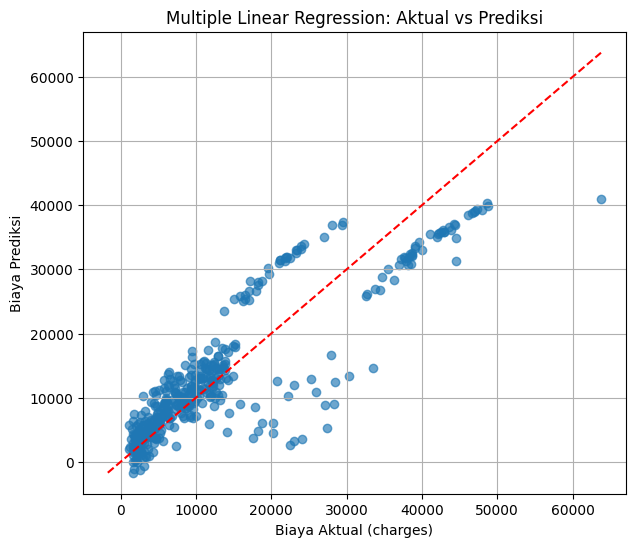

In [24]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_ins, y_pred_ins, alpha=0.65)
batas_min = min(y_test_ins.min(), y_pred_ins.min())
batas_max = max(y_test_ins.max(), y_pred_ins.max())
plt.plot([batas_min, batas_max], [batas_min, batas_max], "r--")
plt.xlabel("Biaya Aktual (charges)")
plt.ylabel("Biaya Prediksi")
plt.title("Multiple Linear Regression: Aktual vs Prediksi")
plt.grid(True)
plt.show()

### 7. Analisis Hasil

- **R-squared** menunjukkan seberapa besar variasi biaya medis yang dapat dijelaskan model. Semakin mendekati 1, semakin baik kecocokan model pada data uji.
- **MAE** adalah rata-rata selisih absolut antara biaya aktual dan prediksi; nilainya menggunakan satuan `charges`.
- **MSE** adalah rata-rata kuadrat kesalahan, sehingga kesalahan besar mendapat penalti lebih besar.
- Pada grafik aktual vs prediksi, titik yang dekat dengan garis merah putus-putus menunjukkan prediksi yang mendekati nilai aktual.


Kesimpulan:

Berdasarkan hasil pengujian, metode Multiple Linear Regression mampu memprediksi biaya asuransi dengan nilai R-squared sebesar 76,96%. Artinya, model sudah cukup baik dalam memperkirakan biaya asuransi berdasarkan data yang digunakan.

Namun, hasil prediksi masih memiliki selisih dengan biaya sebenarnya, terutama pada beberapa data dengan biaya tinggi. Jadi, model ini cukup baik untuk digunakan, tetapi masih bisa ditingkatkan agar hasil prediksinya lebih akurat.